# Off-axis mirrors and nodal aberrations: unobscured telescopes, freeforms and misalignment

A reflecting telescope with a secondary in front of its primary loses light
to the central obscuration and puts diffraction spikes from the spider into
every image. Spectrometers, Earth observation cameras, infrared instruments
and the projection optics of EUV lithography therefore use mirror systems
that are **unobscured**: every mirror is an off-axis piece of a parent
surface, and the light passes beside the other mirrors instead of through
a hole. Two things make such systems harder than the coaxial telescopes of
notebook [97 (telescope zoo)](97_telescope_zoo.ipynb):

- their aberrations no longer depend on the field radius alone, and the
  familiar Seidel picture (one centre of symmetry, the axis) breaks down;
- their mirrors have no axis of their own, so freeform surfaces, which are
  not rotationally symmetric, become natural.

**Nodal aberration theory** (Shack and Thompson, 1980; Thompson, 2005) is
the extension of Seidel theory to systems without symmetry. Each surface
still contributes its Seidel aberrations, but centred on its own point of
the field. The sum of shifted aberration fields has **nodes**, points
where an aberration vanishes, that wander off the axis or split: a
misaligned Ritchey–Chrétien has coma that is the same over the whole field
and **binodal astigmatism**.

| section | content |
|---|---|
| 1 | off-axis segments of conics: what an off-axis paraboloid looks like, and why it has linear astigmatism |
| 2 | nodal aberration theory on a misaligned Ritchey–Chrétien: constant coma, binodal astigmatism, the coma-free pivot |
| 3 | freeform surfaces in nodal aberration theory |
| 4 | an unobscured three-mirror anastigmat, offset in aperture and field, and ring fields |
| 5 | the same telescope with freeform mirrors |
| 6 | summary |

The tools are in `pyoptics.off_axis` (segments, fields, clearance,
layouts and full-field displays, a Cook three-mirror anastigmat) and
`pyoptics.nodal` (the theory), on top of `pyoptics.raytrace` and the
damped least squares optimizer of `pyoptics.lens_optimization`.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import telescopes as tl
from pyoptics import off_axis as oa
from pyoptics import nodal as nd
from pyoptics import lens_optimization as lo

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
WL = 550e-6          # mm
DEG = np.radians(1)
t_start = time.time()


def astig(Z):
    """Astigmatism Z5 + i Z6 (waves) of Fringe Zernike rows."""
    return Z[..., 4] + 1j*Z[..., 5]


def coma(Z):
    """Coma Z7 + i Z8."""
    return Z[..., 6] + 1j*Z[..., 7]

## 1. Off-axis segments

### The shape of an off-axis paraboloid

Cut a disk of radius $a$ out of a paraboloid of focal length $f$, centred
at the height $h$ above its axis, and look at it along its own normal. In
this tangent frame the segment is not a paraboloid any more. Its local
radii of curvature are, for a conic of vertex radius $R$ and conic
constant $K$,

$$R_s = \sqrt{R^2 - K h^2}\ \text{(sagittal)}, \qquad R_t = \frac{R_s^3}{R^2}\ \text{(tangential)},$$

so the cap is astigmatic, by $a^2 (1/R_s - 1/R_t)/4$ of Fringe Z5, and it
has coma and higher terms on top. An optician who polishes an off-axis
paraboloid has to put in exactly these departures; this is what makes
off-axis aspheres expensive, and what makes the outer segments of a
segmented primary (notebook [98 (segmented mirrors)](98_segmented_mirrors.ipynb))
all different. `off_axis.segment_zernikes()` fits Fringe Zernikes to the
segment sag in its tangent frame.

In [2]:
f, a = 500.0, 50.0          # paraboloid f = 500 mm, segments of 100 mm diameter
R, K = -2*f, -1.0
for h in (0.0, 100.0, 200.0, 300.0):
    g = oa.off_axis_conic(R, K, h)
    z = oa.segment_zernikes(R, K, h, a, n_terms=16)
    z4, z5 = a**2/8*(1/g.R_sagittal + 1/g.R_tangential), a**2/4*(1/g.R_sagittal - 1/g.R_tangential)
    print(f"h = {h:5.0f} mm: off-axis angle {2*np.degrees(g.normal_angle):+6.2f}°, "
          f"R_s = {g.R_sagittal:8.1f}, R_t = {g.R_tangential:8.1f} mm")
    print(f"   Z4 {z[3]*1e3:9.2f} µm (closed form {z4*1e3:9.2f}), Z5 {z[4]*1e3:7.2f} µm "
          f"(closed form {z5*1e3:7.2f}), Z8 {z[7]*1e3:6.2f} µm, Z9 {z[8]*1e3:6.3f} µm")

h =     0 mm: off-axis angle  -0.00°, R_s =  -1000.0, R_t =  -1000.0 mm
   Z4   -625.00 µm (closed form   -625.00), Z5    0.00 µm (closed form    0.00), Z8   0.00 µm, Z9 -0.000 µm
h =   100 mm: off-axis angle -11.42°, R_s =  -1005.0, R_t =  -1015.0 mm
   Z4   -618.83 µm (closed form   -618.82), Z5   -6.15 µm (closed form   -6.16), Z8   2.03 µm, Z9 -0.004 µm
h =   200 mm: off-axis angle -22.62°, R_s =  -1019.8, R_t =  -1060.6 mm
   Z4   -601.12 µm (closed form   -601.08), Z5  -23.53 µm (closed form  -23.57), Z8   3.74 µm, Z9 -0.013 µm
h =   300 mm: off-axis angle -33.40°, R_s =  -1044.0, R_t =  -1138.0 mm
   Z4   -574.00 µm (closed form   -573.93), Z5  -49.36 µm (closed form  -49.43), Z8   4.94 µm, Z9 -0.025 µm


The second order terms agree with the closed forms (the small rest is the
fourth order part of the cap). At an off-axis angle of 23°, a 100 mm
segment of an f = 500 mm paraboloid has 24 µm of astigmatism and 4 µm
of coma over its best-fit sphere. The same holds for segmented primaries:
the segments of the 6.5 m primary of the JWST (R = 15.88 m, K = −0.9967,
segments 1.32 m across the flats) carry 50 µm of astigmatism in the
inner ring and 180 µm, with 30 µm of coma, at the outer corners.

JWST-like segment 1.32 m off the axis: Z5 =  -46.7 µm, Z8 = 15.45 µm
JWST-like segment 2.29 m off the axis: Z5 = -137.7 µm, Z8 = 25.82 µm
JWST-like segment 2.64 m off the axis: Z5 = -181.2 µm, Z8 = 29.23 µm


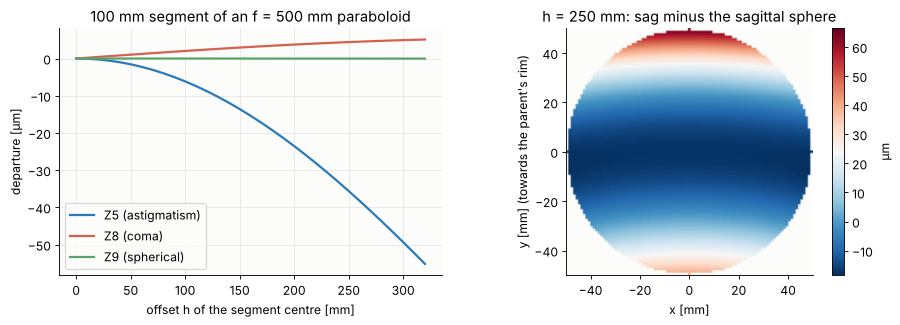

In [3]:
R_jwst, K_jwst, a_seg = -15880.0, -0.9967, 660.0
for h in (1320.0, 2290.0, 2640.0):
    z = oa.segment_zernikes(R_jwst, K_jwst, h, a_seg, n_terms=9)
    print(f"JWST-like segment {h/1e3:4.2f} m off the axis: Z5 = {z[4]*1e3:6.1f} µm, "
          f"Z8 = {z[7]*1e3:5.2f} µm")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
hs = np.linspace(0, 320, 33)
zs = np.array([oa.segment_zernikes(R, K, h, a, n_terms=9) for h in hs])
ax[0].plot(hs, zs[:, 4]*1e3, color=BLUE, lw=2, label="Z5 (astigmatism)")
ax[0].plot(hs, zs[:, 7]*1e3, color=RED, lw=2, label="Z8 (coma)")
ax[0].plot(hs, zs[:, 8]*1e3, color=GREEN, lw=2, label="Z9 (spherical)")
ax[0].set(xlabel="offset h of the segment centre [mm]", ylabel="departure [µm]",
          title="100 mm segment of an f = 500 mm paraboloid")
ax[0].legend()
u = np.linspace(-1, 1, 101)
U, V = np.meshgrid(u, u)
z = oa.segment_sag(R, K, 250.0, a*U, a*V)
g = oa.off_axis_conic(R, K, 250.0)
sph = (a*U)**2/(2*g.R_sagittal) + (a*V)**2/(2*g.R_sagittal)
dep = np.where(U**2 + V**2 <= 1, z - sph, np.nan)
im = ax[1].imshow((dep - np.nanmean(dep))*1e3, extent=[-a, a, -a, a], origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=ax[1], label="µm")
ax[1].set(xlabel="x [mm]", ylabel="y [mm] (towards the parent's rim)",
          title="h = 250 mm: sag minus the sagittal sphere")
ax[1].grid(False)
plt.tight_layout()
plt.show()

### Offset in aperture: the off-axis paraboloid in the ray tracer

An off-axis system is traced as its rotationally symmetric parent with an
**aperture offset**: the stop is a plane dummy surface in front of the
mirror, decentred by $h$ (`off_axis.off_axis_parabola()`). Ray aiming
finds the centre of the decentred stop; the paraxial data, the Seidel sums
and the pupils are those of the parent.

On the axis the off-axis paraboloid is perfect, as its parent. Off the
axis the parent has coma, $W_{131} (\mathbf H\cdot\boldsymbol\rho)(\boldsymbol\rho\cdot\boldsymbol\rho)$.
The sub-aperture sees this coma around the pupil point
$\mathbf s = (0, h/a)$: writing $\boldsymbol\rho = \mathbf s + \mathbf q$
and collecting the terms quadratic in the sub-aperture coordinate
$\mathbf q$ gives defocus and astigmatism proportional to
$W_{131}\,\mathbf H\cdot\mathbf s$: **linear astigmatism**, which grows
with the field angle itself and not with its square, and a tilted image
plane. `nodal.nat_zernikes()` with a `pupil_offset` samples the third
order wavefront of the parent over the sub-aperture.

In [4]:
h_oap, D_oap, fld = 150.0, 100.0, 1.0*DEG
oap = oa.off_axis_parabola(f, h_oap, D_oap, field_angle=fld)
F_oap = oa.rectangular_field((0, 0), (fld, fld), (5, 5))
H_oap = nd.complex_field(F_oap, fld)
Z_oap = oa.field_zernikes(oap, F_oap, 9)
nat_oap = nd.nat_zernikes(nd.nodal_coefficients(oap), H_oap, 9, pupil_offset=1j*h_oap/(D_oap/2))
print("off-axis paraboloid, f = 500 mm, D = 100 mm, offset 150 mm, ±1° field")
print("field (x, y) [°]   ray trace Z4   Z5     Z6     Z7    Z8   |  NAT Z4   Z5     Z6     Z7    Z8 [waves]")
for k in (0, 2, 12, 14, 22, 24):
    print(f"  ({F_oap[k, 0]/DEG:+.1f}, {F_oap[k, 1]/DEG:+.1f})      "
          + " ".join(f"{v:6.2f}" for v in Z_oap[k, 3:8]) + "  | "
          + " ".join(f"{v:6.2f}" for v in nat_oap[k, 3:8]))
err = np.max(np.abs(Z_oap[:, 3:8] - nat_oap[:, 3:8]))
print(f"largest difference {err:.2f} waves of {np.max(np.abs(Z_oap[:, 3:8])):.1f}")

off-axis paraboloid, f = 500 mm, D = 100 mm, offset 150 mm, ±1° field
field (x, y) [°]   ray trace Z4   Z5     Z6     Z7    Z8   |  NAT Z4   Z5     Z6     Z7    Z8 [waves]
  (-1.0, -1.0)      -11.94  11.70 -12.37  -1.26  -1.16  | -11.90  11.90 -12.59  -1.32  -1.32
  (+0.0, -1.0)      -11.92  12.04   0.00  -0.00  -1.16  | -11.90  12.25  -0.00  -0.00  -1.32
  (+0.0, +0.0)       -0.00   0.00   0.00   0.00   0.00  |  -0.00   0.00  -0.00   0.00  -0.00
  (+1.0, +0.0)       -0.02  -0.34  11.60   1.26  -0.01  |  -0.00  -0.35  11.90   1.32  -0.00
  (+0.0, +1.0)       11.81 -11.15   0.00  -0.00   1.14  |  11.90 -11.55   0.00  -0.00   1.32
  (+1.0, +1.0)       11.78 -11.49  10.80   1.25   1.13  |  11.90 -11.90  11.21   1.32   1.32
largest difference 0.41 waves of 12.4


Twelve waves of astigmatism at one degree, against 1.3 waves of coma: an
off-axis paraboloid is useful only over a small field. The prediction
from the parent's third order coefficients agrees with the ray trace to
3 %. Plotting the astigmatism over the field as sticks (length the
magnitude $|Z_5 + i Z_6|$, direction the axis of the astigmatism, half
the angle of $Z_5 + i Z_6$) is the **full-field display** that
Thompson's group uses throughout; for linear astigmatism the sticks grow
linearly away from the centre, where their single node sits.

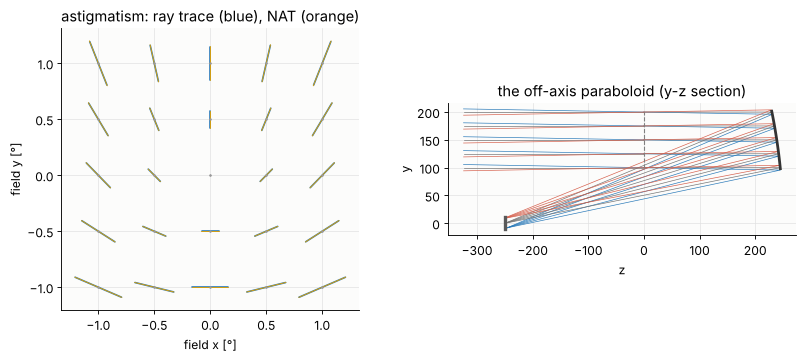

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6))
sc = oa.plot_full_field(ax[0], F_oap, astig(Z_oap), "astigmatism", unit=DEG, color=BLUE)
oa.plot_full_field(ax[0], F_oap, astig(nat_oap), "astigmatism", unit=DEG, color=ORANGE, lw=0.8,
                   scale=sc)
ax[0].set(xlabel="field x [°]", ylabel="field y [°]",
          title="astigmatism: ray trace (blue), NAT (orange)")
oa.draw_layout(oap, [(0, -fld), (0, 0), (0, fld)], ax=ax[1], colors=[BLUE, GREY, RED], n_rays=5)
ax[1].set(title="the off-axis paraboloid (y-z section)")
plt.tight_layout()
plt.show()

## 2. Nodal aberration theory on a misaligned Ritchey–Chrétien

The Ritchey–Chrétien of notebook [97 (telescope zoo)](97_telescope_zoo.ipynb):
D = 1 m, primary f₁ = 3 m, system f = 8 m, back focus 300 mm behind the
primary, ±0.25° field. It is aplanatic: no spherical aberration and no
coma, the field is limited by astigmatism.

Nodal aberration theory writes the third order wavefront of a system
without symmetry as the sum over its surfaces $j$ of their Seidel terms
with the field vector $\mathbf H$ replaced by $\mathbf H - \boldsymbol\sigma_j$:

$$W = \sum_j \Big[W_{040j} (\boldsymbol\rho\cdot\boldsymbol\rho)^2 + W_{131j} \big((\mathbf H - \boldsymbol\sigma_j)\cdot\boldsymbol\rho\big)(\boldsymbol\rho\cdot\boldsymbol\rho) + \tfrac12 W_{222j} \big((\mathbf H - \boldsymbol\sigma_j)^2\cdot\boldsymbol\rho^2\big) + W_{220Mj} |\mathbf H - \boldsymbol\sigma_j|^2 (\boldsymbol\rho\cdot\boldsymbol\rho) + \dots\Big].$$

$\boldsymbol\sigma_j$ is the field point whose chief ray passes through
the centre of curvature of the surface (for its spherical part) or
through its vertex (for its aspheric part), measured from the optical
axis ray (the ray from the field centre through the centre of the stop).
For a surface decentred by $\mathbf d$ and tilted by $\boldsymbol\alpha$,
$\boldsymbol\sigma_{\rm sph} = n c\,\delta\mathbf C/\bar A$ and
$\boldsymbol\sigma_{\rm asph} = \mathbf d/\bar y$, with the shift
$\delta\mathbf C$ of its centre of curvature, the chief ray height
$\bar y$ and the refraction invariant $\bar A = n(\bar u + \bar y c)$ of
the chief ray at full field.

In complex notation ($\mathbf H \to H_x + iH_y$, vector squares are
complex squares), the sums collapse to a few vectors:

- **coma** $Z_7 + iZ_8 = (W_{131} H - A_{131})/3$, $A_{131} = \sum_j W_{131j}\sigma_j$.
  For an aplanatic telescope $W_{131} = 0$: a misalignment gives coma that
  is **constant over the field**.
- **astigmatism** $Z_5 + iZ_6 = \tfrac12 (W_{222} H^2 - 2A_{222}H + B_{222})$,
  $A_{222} = \sum_j W_{222j}\sigma_j$, $B_{222} = \sum_j W_{222j}\sigma_j^2$.
  The quadratic has two roots, the **nodes**: astigmatism becomes
  **binodal**.

The secondary is decentred by 1 mm in y (`nodal.nodal_coefficients()`
reads the decentres and tilts of the surfaces).

In [6]:
D_rc, f1_rc, f_rc, b_rc = 1000.0, 3000.0, 8000.0, 300.0
th = 0.25*DEG
rc = tl.two_mirror_telescope(D_rc, f1_rc, f_rc, b_rc, "rc", wavelength=WL, field_angle=th)
F_rc = oa.rectangular_field((0, 0), (th, th), (7, 7))
H_rc = nd.complex_field(F_rc, th)


def misaligned(decenter=(0.0, 0.0), tilt=(0.0, 0.0, 0.0)):
    s = rc.copy()
    s.surfaces[1].decenter, s.surfaces[1].tilt = decenter, tilt
    return s


Z_rc = oa.field_zernikes(rc, F_rc, 9)
rc_dec = misaligned((0.0, 1.0))
Z_dec = oa.field_zernikes(rc_dec, F_rc, 9)
c_dec = nd.nodal_coefficients(rc_dec)
P_dec = nd.nat_zernikes(c_dec, H_rc)
fit_dec = nd.fit_field(H_rc, Z_dec)
print(f"aligned RC: W040 = {c_dec.W040:.1e}, W131 = {c_dec.W131:.1e}, W222 = {c_dec.W222:.3f} waves "
      f"at 0.25°")
print("secondary decentred by 1 mm:        NAT          fit to the ray trace")
print(f"  constant coma -A131/3  [waves] {-c_dec.A131/3:.3f}    {-fit_dec.A131/3:.3f}")
print(f"  A222                   [waves] {c_dec.A222:.4f}   {fit_dec.A222:.4f}")
print(f"  B222                   [waves] {c_dec.B222:.4f}   {fit_dec.B222:.4f}")
print("  nodes of astigmatism [°]:      ",
      "  ".join(f"({n.real*th/DEG:+.4f}, {n.imag*th/DEG:+.4f})" for n in nd.astigmatic_nodes(c_dec)),
      "\n                       fit:      ",
      "  ".join(f"({n.real*th/DEG:+.4f}, {n.imag*th/DEG:+.4f})" for n in nd.astigmatic_nodes(fit_dec)))
print(f"largest difference NAT - ray trace in Z5...Z8: "
      f"{np.max(np.abs(Z_dec[:, 4:8] - P_dec[:, 4:8])):.3f} waves")

aligned RC: W040 = -2.1e-14, W131 = -1.1e-14, W222 = -1.566 waves at 0.25°
secondary decentred by 1 mm:        NAT          fit to the ray trace
  constant coma -A131/3  [waves] 0.000+0.744j    0.000+0.736j
  A222                   [waves] 0.0000-0.0646j   0.0000-0.0642j
  B222                   [waves] 0.0094+0.0000j   0.0092+0.0000j
  nodes of astigmatism [°]:       (-0.0164, +0.0103)  (+0.0164, +0.0103) 
                       fit:       (-0.0163, +0.0103)  (+0.0163, +0.0103)
largest difference NAT - ray trace in Z5...Z8: 0.015 waves


The theory reproduces the ray traced coma and astigmatism to about 1 %.
A decentre of 1 mm (0.1 % of the aperture) gives 0.74 waves of coma,
the same everywhere in the field, and splits the single node of
astigmatism at the centre into two nodes, 0.016° apart. The focus (Z4)
shows a tilted image surface as well; on a fixed image plane the tilt
of the beam against the plane (the boresight error) adds to it
(`nodal.boresight_focus()`).

**Coma-free pivot.** Tilting the secondary about its vertex also gives
constant coma, in the other direction. Combined, a tilt about a point on
the axis at the right distance gives none: the coma-free pivot
(`nodal.coma_free_pivot()`). Telescopes are collimated by removing the
coma on the axis, often with a tilt of the secondary about this point.
The full-field displays show what this leaves behind.

coma-free pivot -729 mm from the vertex of the secondary along +z (the secondary's centre of curvature is at -2880 mm)


tilt 0.02° about it: coma 0.010 waves (the same tilt about the vertex: 0.195), nodes at (-0.0000, -0.0177)°  (+0.0000, +0.0006)°


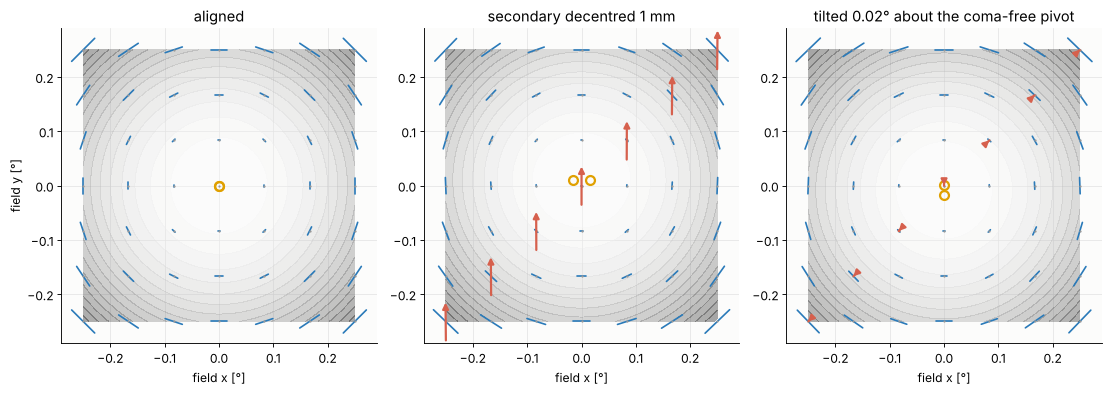

In [7]:
z_p = nd.coma_free_pivot(rc, 1)
alpha = 0.02*DEG
rc_piv = misaligned((0.0, z_p*alpha), (alpha, 0.0, 0.0))
Z_piv = oa.field_zernikes(rc_piv, F_rc, 9)
c_piv = nd.nodal_coefficients(rc_piv)
print(f"coma-free pivot {z_p:.0f} mm from the vertex of the secondary along +z "
      f"(the secondary's centre of curvature is at {rc.surfaces[1].R:.0f} mm)")
print(f"tilt 0.02° about it: coma {np.max(np.abs(coma(Z_piv))):.3f} waves "
      f"(the same tilt about the vertex: "
      f"{np.max(np.abs(coma(oa.field_zernikes(misaligned(tilt=(alpha, 0, 0)), F_rc, 9)))):.3f}), "
      f"nodes at " + "  ".join(f"({n.real*th/DEG:+.4f}, {n.imag*th/DEG:+.4f})°"
                                for n in nd.astigmatic_nodes(c_piv)))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
xs = np.linspace(-th, th, 81)
X, Y = np.meshgrid(xs, xs)
Hg = (X + 1j*Y)/th
for k, (name, Z, c) in enumerate([("aligned", Z_rc, nd.nodal_coefficients(rc)),
                                  ("secondary decentred 1 mm", Z_dec, c_dec),
                                  ("tilted 0.02° about the coma-free pivot", Z_piv, c_piv)]):
    A = np.abs(0.5*(c.W222*Hg**2 - 2*c.A222*Hg + c.B222))
    ax[k].contourf(X/DEG, Y/DEG, A, levels=np.linspace(0, 1.6, 17), cmap="Greys", alpha=0.35)
    sc = oa.plot_full_field(ax[k], F_rc, astig(Z), "astigmatism", unit=DEG, color=BLUE,
                            scale=0.05/1.3)
    if k:
        oa.plot_full_field(ax[k], F_rc[::8], coma(Z[::8]), "coma", unit=DEG, color=RED,
                           scale=0.08/0.75, lw=2)
    n = nd.astigmatic_nodes(c)*th/DEG
    ax[k].plot(n.real, n.imag, "o", ms=8, mfc="none", mec=ORANGE, mew=2)
    ax[k].set(title=name, xlabel="field x [°]", xlim=(-0.29, 0.29), ylim=(-0.29, 0.29))
ax[0].set_ylabel("field y [°]")
plt.tight_layout()
plt.show()

Grey shading: $|Z_5 + iZ_6|$ from nodal aberration theory; blue sticks:
ray traced astigmatism; red arrows: ray traced coma (on the diagonal);
orange circles: the nodes. In the aligned telescope the astigmatism is
zero at the centre and grows with the square of the field. The decentred
secondary adds constant coma and pulls the node apart into two. After
collimation about the coma-free pivot the coma is gone, but the
astigmatism is still binodal: on the axis the telescope looks perfectly
aligned, while the field is not. This is how the misalignment of large
telescopes is diagnosed (Schmid et al. 2010): coma on the axis gives one
combination of decentre and tilt, the positions of the astigmatic nodes
in the field give the other.

## 3. Freeform surfaces in nodal aberration theory

A freeform departure $\Delta(x, y)$ on surface $j$ changes the OPD by
$(n - n')\Delta$ ($2\Delta$ for a mirror) where the beam meets the
surface. At the field $\mathbf H$ the beam covers the disk of radius $y$
(the marginal ray height) around $\bar y\mathbf H$ (the chief ray
height). Expanding a Zernike departure over that moving disk
(Fuerschbach, Rolland and Thompson 2014) gives:

- a freeform term **at the stop** ($\bar y = 0$): the same aberration
  everywhere in the field;
- a freeform term **away from the stop**: its own aberration, constant
  over the field, plus lower order aberrations that grow with the field.
  Coma ($Z_7$, $Z_8$) adds astigmatism linear in $\mathbf H$, astigmatism
  adds a field-linear tilt.

`nodal.freeform_field_zernikes()` does this expansion numerically. Check
on the Ritchey–Chrétien with Z5 or Z8 departures of 0.2 µm on the primary
(the stop) or on the secondary:

In [8]:
fp_rc = oa.footprints(rc, F_rc[[0, 6, 42, 48]])
Z0 = Z_rc
F9 = F_rc[[0, 24, 48]]
print("departure          field [°]       ray trace  Z5+iZ6        Z7+iZ8   | freeform NAT  Z5+iZ6        Z7+iZ8")
for surf, j in [(0, 5), (0, 8), (1, 5), (1, 8)]:
    s = rc.copy()
    S = s.surfaces[surf]
    s.surfaces[surf] = rt.ZernikeSurface(S.R, S.thickness, zernike={j: 2e-4},
                                         norm_radius=fp_rc[surf].radius, conic=S.conic,
                                         mirror=True, semi_diameter=S.semi_diameter)
    dZ = oa.field_zernikes(s, F_rc, 9) - Z0
    P = nd.freeform_field_zernikes(s, surf, H_rc, 9)
    for k in (0, 24, 48):
        print(f"Z{j} on {['primary', 'secondary'][surf]:9s} ({F_rc[k, 0]/DEG:+.2f}, {F_rc[k, 1]/DEG:+.2f})"
              f"   {astig(dZ[k]):14.3f} {coma(dZ[k]):14.3f} | {astig(P[k]):14.3f} {coma(P[k]):14.3f}")

departure          field [°]       ray trace  Z5+iZ6        Z7+iZ8   | freeform NAT  Z5+iZ6        Z7+iZ8


Z5 on primary   (-0.25, -0.25)     0.724-0.000j  -0.000+0.000j |   0.727+0.000j   0.000-0.000j
Z5 on primary   (+0.00, +0.00)     0.724+0.000j  -0.000-0.000j |   0.727+0.000j   0.000-0.000j
Z5 on primary   (+0.25, +0.25)     0.724-0.000j   0.000-0.000j |   0.727+0.000j   0.000-0.000j


Z8 on primary   (-0.25, -0.25)     0.001-0.001j  -0.000+0.725j |   0.000+0.000j  -0.000+0.727j
Z8 on primary   (+0.00, +0.00)    -0.000+0.000j  -0.000+0.725j |   0.000+0.000j  -0.000+0.727j
Z8 on primary   (+0.25, +0.25)    -0.001+0.001j  -0.000+0.725j |   0.000+0.000j  -0.000+0.727j


Z5 on secondary (-0.25, -0.25)    -0.611-0.000j   0.000-0.000j |  -0.611-0.000j  -0.000-0.000j
Z5 on secondary (+0.00, +0.00)    -0.611-0.000j  -0.000-0.000j |  -0.611-0.000j  -0.000-0.000j
Z5 on secondary (+0.25, +0.25)    -0.611-0.000j  -0.000+0.000j |  -0.611+0.000j  -0.000+0.000j


Z8 on secondary (-0.25, -0.25)    -0.104+0.104j  -0.000-0.564j |  -0.103+0.103j  -0.000-0.560j
Z8 on secondary (+0.00, +0.00)     0.000-0.000j  -0.000-0.564j |  -0.000+0.000j   0.000-0.560j
Z8 on secondary (+0.25, +0.25)     0.104-0.104j  -0.000-0.564j |   0.103-0.103j  -0.000-0.560j


On the primary, the stop of this telescope, the freeform astigmatism and
coma are the same at every field point. On the secondary the Z8 coma
term adds astigmatism that is linear in the field (opposite signs at
opposite corners) and zero at the centre. This is the design rule for
freeform telescopes: a freeform near the stop removes field-constant
aberrations, one away from it field-dependent ones, and the theory says
which term on which mirror does what before any optimization (Bauer,
Schiesser and Rolland 2018).

## 4. An unobscured three-mirror anastigmat

Three mirrors have enough freedom for a flat-field anastigmat: three
curvatures and two separations set the focal length and a zero Petzval
sum ($c_1 - c_2 + c_3 = 0$ for three mirrors), and three conic constants
remove spherical aberration, coma and astigmatism (the Seidel sums are
linear in the conic constants, `off_axis.solve_conics()`). Cook's
three-mirror anastigmat (US 4,265,510) has a concave primary, a convex
secondary that is the aperture stop and a concave tertiary. Used
**off-axis in aperture and field**, it is unobscured: the stop is
decentred (an aperture offset) and the field is biased to one side of the
axis, so that primary and tertiary sit on opposite sides and the beams
pass beside the mirrors.

Specification: f = 600 mm, F/4 (150 mm entrance pupil), a 3° × 1° field
centred 3° off the axis, 550 nm. The parent from `off_axis.cook_tma()`,
with the stop decentred by twice its semi diameter:

In [9]:
EFL, FNUM = 600.0, 4.0
tma = oa.cook_tma(efl=EFL, f_number=FNUM, field_angle=4.0*DEG,
                  prescription=(-2/3, 0.2, -1/3, 4/9), aperture_offset=-2.0)
centre = (0.0, 3.0*DEG)
F_tma = oa.rectangular_field(centre, (1.5*DEG, 0.5*DEG), (5, 3))     # 5 x 3 field points
F_corners = oa.rectangular_field(centre, (1.5*DEG, 0.5*DEG), (3, 3))
print(tma)
sd = tma.seidel()
print("\nSeidel sums of the parent S_I...S_V [mm]:", np.array2string(sd.total, precision=2))
p = tma.paraxial()
print(f"efl {p.efl:.1f} mm, F/{p.f_number:.2f}, entrance pupil {2*p.ep_radius:.0f} mm")
c_tma = nd.nodal_coefficients(tma)
print(f"third order: W040 {c_tma.W040:.1e}, W131 {c_tma.W131:.1e}, W222 {c_tma.W222:.1e}, "
      f"W220M {c_tma.W220M:.1e} waves")

System(wavelength=0.00055, stop_index=1, object_distance=inf, max_field=0.06981317007977318)
   0  Mirror(R=-399.99999999999983, thickness=-119.99999999999996, n_after=None, material=None, conic=-1.111809923130678, aspheric=(), semi_diameter=None) n'=1.000000
   1* Surface(R=inf, thickness=0.0, n_after=None, material=None, conic=0.0, aspheric=(), semi_diameter=30.0) n'=1.000000
   2  Mirror(R=-199.99999999999991, thickness=266.6666666666666, n_after=None, material=None, conic=-2.7853009259259283, aspheric=(), semi_diameter=None) n'=1.000000
   3  Mirror(R=-399.99999999999983, thickness=-80.0, n_after=None, material=None, conic=-9.101415094339607, aspheric=(), semi_diameter=None) n'=1.000000

Seidel sums of the parent S_I...S_V [mm]: [ 3.83e-16  7.63e-17  9.02e-17  0.00e+00 -3.70e-01]
efl 600.0 mm, F/4.00, entrance pupil 150 mm
third order: W040 -8.7e-14, W131 -9.9e-14, W222 -6.4e-14, W220M -9.9e-14 waves


**Clearance.** `off_axis.beam_clearance()` traces rays at the corners and
edges of the field, takes the footprint of every mirror (and of the
detector) and asks for each beam between two surfaces whether it crosses
another mirror inside its footprint, and how far it passes from its rim.

closest approach of each beam to each mirror [mm] (negative: blocked, '-': never crosses it)
                incoming     M1 → stop     stop → M2       M2 → M3    M3 → image
        M1             -             -             -          49.5             -
        M2          17.7             -             -             -             -
        M3             -             -             -             -             -
     image             -             -             -          12.1             -
   M1: footprint centre y =  -139.3 mm, radius  72.2 mm
 stop: footprint centre y =    -0.0 mm, radius  30.0 mm
   M2: footprint centre y =   -51.1 mm, radius  27.5 mm
   M3: footprint centre y =    19.5 mm, radius  27.3 mm


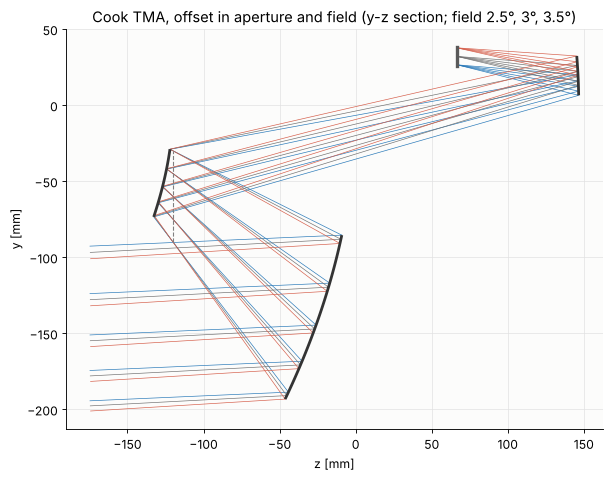

In [10]:
cl = oa.beam_clearance(tma, F_corners)
beam_names = ["incoming"] + [f"{(tma.surfaces[k].label or 'stop')} → "
                             f"{(tma.surfaces[k + 1].label if k + 1 < len(tma.surfaces) else 'image')}"
                             for k in range(len(tma.surfaces))]
print("closest approach of each beam to each mirror [mm] (negative: blocked, '-': never crosses it)")
print(" " * 10 + "".join(f"{b:>14s}" for b in beam_names))
for name, row in zip(cl.names, cl.distance):
    print(f"{name:>10s}" + "".join(f"{'-' if not np.isfinite(v) else f'{v:.1f}':>14s}" for v in row))
fp = oa.footprints(tma, F_corners)
for i, s in enumerate(tma.surfaces):
    print(f"{s.label:>5s}: footprint centre y = {fp[i].centre[1]:7.1f} mm, radius {fp[i].radius:5.1f} mm")

fig, ax = plt.subplots(figsize=(11, 6.5))
oa.draw_layout(tma, [(0, 2.5*DEG), (0, 3.0*DEG), (0, 3.5*DEG)], ax=ax,
               colors=[BLUE, GREY, RED], n_rays=5)
ax.set(title="Cook TMA, offset in aperture and field (y-z section; field 2.5°, 3°, 3.5°)",
       xlabel="z [mm]", ylabel="y [mm]")
plt.show()

All beams clear the mirrors with 12 mm or more to spare. The tightest
spots are the detector, next to the beam from the secondary to the
tertiary, and the secondary, a small mirror next to the incoming beam. The
parent is a perfect anastigmat to third order (all five coefficients
vanish), so nodal aberration theory predicts no aberrations at all for
its off-axis part. What the ray trace finds is **fifth and higher
order**: the used aperture reaches three semi diameters out into the
parent pupil, so the parent works at an effective F/1.3 and its higher
order aberrations are large.

In [11]:
rms_conic = oa.field_rms(tma, F_tma)
Z_tma = oa.field_zernikes(tma, F_tma, 16)
print("RMS wavefront error [waves] over the field (rows: field y = 2.5°, 3°, 3.5°; columns: x = -1.5 ... 1.5°)")
print(np.array2string(rms_conic.reshape(3, 5), precision=3))
print(f"largest Zernikes: Z4 {np.max(np.abs(Z_tma[:, 3])):.2f}, astigmatism "
      f"{np.max(np.abs(astig(Z_tma))):.2f}, coma {np.max(np.abs(coma(Z_tma))):.2f}, "
      f"Z9 {np.max(np.abs(Z_tma[:, 8])):.2f}, Z10/11 "
      f"{np.max(np.abs(Z_tma[:, 9] + 1j*Z_tma[:, 10])):.2f} waves")

RMS wavefront error [waves] over the field (rows: field y = 2.5°, 3°, 3.5°; columns: x = -1.5 ... 1.5°)
[[0.194 0.27  0.303 0.27  0.194]
 [0.194 0.09  0.095 0.09  0.194]
 [0.398 0.156 0.126 0.156 0.398]]
largest Zernikes: Z4 0.38, astigmatism 0.87, coma 0.30, Z9 0.06, Z10/11 0.41 waves


Up to 0.4 waves RMS against the diffraction limit of 0.07 waves
(Maréchal). A conic-only optimization (the three conic constants, the
image distance and an image plane tilt) can balance the higher orders a
little. The operands are `off_axis.field_wavefront()` (the OPD over the
full pupil at two-dimensional field points, tilt removed) and
`off_axis.focal_length()` (the image scale from real chief rays, held at
600 mm); the variables include `lens_optimization.ImageTilt`.

In [12]:
operands = [oa.field_wavefront(F_corners, tolerance=0.01),
            oa.focal_length(EFL, centre, tolerance=0.5)]
conic_vars = [lo.Conic(0), lo.Conic(2), lo.Conic(3), lo.Thickness(3), lo.ImageTilt(0, (-0.05, 0.05))]
t0 = time.time()
opt = lo.DampedLeastSquares(tma, conic_vars, operands)
res_conic = opt.run(max_iterations=30)
tma_conic = opt.system
rms_conic2 = oa.field_rms(tma_conic, F_tma)
print(f"{res_conic.message} after {len(res_conic.history) - 1} iterations, {time.time() - t0:.0f} s")
print("conic constants", [f"{tma_conic.surfaces[i].conic:.3f}" for i in (0, 2, 3)],
      f"image tilt {np.degrees(tma_conic.image_tilt[0]):.3f}°")
print("RMS [waves]:\n" + np.array2string(rms_conic2.reshape(3, 5), precision=3))

converged after 6 iterations, 1 s
conic constants ['-1.113', '-2.792', '-9.707'] image tilt -0.225°
RMS [waves]:
[[0.216 0.292 0.317 0.292 0.216]
 [0.121 0.111 0.085 0.111 0.121]
 [0.284 0.19  0.185 0.19  0.284]]


### Ring fields

A coaxial parent has aberrations that depend only on the distance from the
axis. A field that is an arc of a ring around the axis therefore sees the
same correction along its whole length, which is why the slit of
lithographic scanners (Offner relays, EUV projection optics) is a ring
field: it is long in one direction for a cheap scan, and it lives in the
zone where the higher order aberrations of the parent are balanced.
Without an aperture offset (the obscured parent, as the EUV projectors use
it with a centred pupil) the RMS of the conic TMA depends only on the
field radius. A conic optimization on an arc at 3°
(`off_axis.ring_field()`, here at F/6) moves the best zone from the axis
onto the ring.

RMS along the arc at 2.9° from 60° to 120° azimuth: 0.068 ... 0.069 waves
RMS along the arc at 3.0° from 60° to 120° azimuth: 0.036 ... 0.036 waves
RMS along the arc at 3.1° from 60° to 120° azimuth: 0.076 ... 0.076 waves
rectangle 3.1° x 0.2° centred at 3° (the same area): RMS up to 0.433 waves


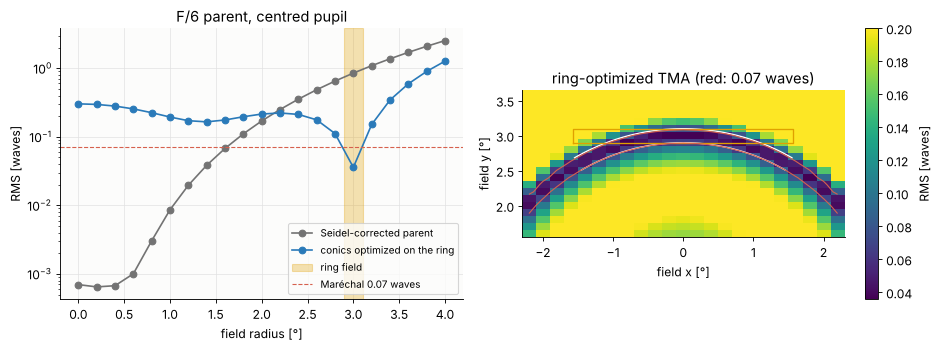

In [13]:
parent = oa.cook_tma(efl=EFL, f_number=6.0, field_angle=4.0*DEG,
                     prescription=(-2/3, 0.2, -1/3, 4/9))
arc = oa.ring_field(3.0*DEG, np.radians(30.0), width=0.2*DEG, n_arc=4, n_radial=3)
opt_ring = lo.DampedLeastSquares(parent, [lo.Conic(0), lo.Conic(1), lo.Conic(2), lo.Thickness(2)],
                                 [oa.field_wavefront(arc, tolerance=0.01)])
opt_ring.run(max_iterations=30)
ring_tma = opt_ring.system
radii = np.linspace(0, 4.0, 21)*DEG
rms_r0 = [parent.rms_opd((0.0, r), N=32) for r in radii]
rms_r1 = [ring_tma.rms_opd((0.0, r), N=32) for r in radii]
az = np.radians(np.linspace(60, 120, 13))
for r in (2.9, 3.0, 3.1):
    rms_arc = [ring_tma.rms_opd((r*DEG*np.cos(t), r*DEG*np.sin(t)), N=32) for t in az]
    print(f"RMS along the arc at {r}° from 60° to 120° azimuth: "
          f"{min(rms_arc):.3f} ... {max(rms_arc):.3f} waves")
F_rect = oa.rectangular_field((0, 3*DEG), (1.57*DEG, 0.1*DEG), (7, 3))
print(f"rectangle 3.1° x 0.2° centred at 3° (the same area): RMS up to "
      f"{np.max(oa.field_rms(ring_tma, F_rect)):.3f} waves")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].semilogy(radii/DEG, rms_r0, "o-", color=GREY, label="Seidel-corrected parent")
ax[0].semilogy(radii/DEG, rms_r1, "o-", color=BLUE, label="conics optimized on the ring")
ax[0].axvspan(2.9, 3.1, color=ORANGE, alpha=0.3, label="ring field")
ax[0].axhline(0.07, color=RED, ls="--", lw=1, label="Maréchal 0.07 waves")
ax[0].set(xlabel="field radius [°]", ylabel="RMS [waves]", title="F/6 parent, centred pupil")
ax[0].legend(fontsize=9)
xs = np.linspace(-2.2, 2.2, 23)*DEG
ys = np.linspace(1.6, 3.6, 21)*DEG
vals = np.array([[ring_tma.rms_opd((x, y), N=24) for x in xs] for y in ys])
img = ax[1].pcolormesh(xs/DEG, ys/DEG, vals, cmap="viridis", shading="nearest", vmax=0.2)
plt.colorbar(img, ax=ax[1], label="RMS [waves]")
t = np.radians(np.linspace(60, 120, 60))
for r in (2.9, 3.1):
    ax[1].plot(r*np.cos(t), r*np.sin(t), color="w", lw=1.2)
ax[1].plot([-1.57, 1.57, 1.57, -1.57, -1.57], [2.9, 2.9, 3.1, 3.1, 2.9], color=ORANGE, lw=1.2)
ax[1].contour(xs/DEG, ys/DEG, vals, levels=[0.07], colors=RED, linewidths=1)
ax[1].set(xlabel="field x [°]", ylabel="field y [°]", aspect="equal",
          title="ring-optimized TMA (red: 0.07 waves)")
ax[1].grid(False)
plt.tight_layout()
plt.show()

The ring-optimized parent is diffraction limited in a band about 0.2°
wide around the 3° circle, along the whole 60° arc (3.1° long): the
correction follows the radius, not the azimuth. A straight slit of the
same length and width (orange) leaves the band at its ends. The price is
the speed: at F/4 the same band is about 0.12 waves; EUV projectors pay
with six mirrors instead of three.

## 5. Freeform mirrors

Now each mirror gets a freeform departure: Fringe Zernikes centred on its
footprint (`off_axis.freeform_mirrors()`, a `raytrace.ZernikeSurface`
with a `centre`), the terms that keep the y-z plane a plane of symmetry
(Z4, Z5, Z8, Z9, Z11, Z12, Z15, Z16), plus the conics, the image
distance and the image tilt (held within ±3°): 29 variables for
`lens_optimization.DampedLeastSquares` (`lens_optimization.ZernikeTerm`).
A clearance operand (`off_axis.clearance_penalty()`) keeps 5 mm between
the beams and the mirrors. The mirror tilts could be variables too
(`lens_optimization.Tilt`); here they are not needed, and left free they
ran off to several degrees for little gain. With analytic derivatives of
the ray trace (`jac="analytic"`: the wavefront, focal length and clearance
operands are all differentiated analytically) the optimization takes
about half a minute instead of ten.

In [14]:
ff = oa.freeform_mirrors(tma_conic, F_corners)
terms = [4, 5, 8, 9, 11, 12, 15, 16]
ff_vars = conic_vars + lo.zernike_terms(ff, [0, 2, 3], terms)
operands_ff = operands + [oa.clearance_penalty(F_corners, minimum=5.0, tolerance=0.05)]
t0 = time.time()
opt_ff = lo.DampedLeastSquares(ff, ff_vars, operands_ff, jac="analytic")
res_ff = opt_ff.run(max_iterations=25)
tma_ff = opt_ff.system
t_ff = time.time() - t0
rms_ff = oa.field_rms(tma_ff, F_tma)
print(f"{len(ff_vars)} variables, {res_ff.message} after {len(res_ff.history) - 1} iterations, "
      f"{t_ff:.0f} s; merit {res_conic.merit:.0f} -> {res_ff.merit:.0f}")
print("RMS [waves]:\n" + np.array2string(rms_ff.reshape(3, 5), precision=3))
print(f"image tilt {np.degrees(tma_ff.image_tilt[0]):.2f}°; conic constants "
      + ", ".join(f"{tma_conic.surfaces[i].conic:.3f} -> {tma_ff.surfaces[i].conic:.3f}"
                  for i in (0, 2, 3)))
f_real = EFL + oa.focal_length(EFL, centre, tolerance=1.0)(tma_ff)
print(f"focal length from real chief rays (x, y): {f_real[0]:.2f}, {f_real[1]:.2f} mm")
print("closest approach of a beam to a mirror: "
      f"{np.min(oa.beam_clearance(tma_ff, F_corners).distance):.1f} mm")

29 variables, maximum number of iterations after 25 iterations, 32 s; merit 157111 -> 2707
RMS [waves]:
[[0.03  0.043 0.043 0.043 0.03 ]
 [0.026 0.03  0.04  0.03  0.026]
 [0.023 0.033 0.024 0.033 0.023]]
image tilt 2.44°; conic constants -1.113 -> -1.149, -2.792 -> -2.406, -9.707 -> -4.374
focal length from real chief rays (x, y): 595.71, 607.88 mm
closest approach of a beam to a mirror: 17.8 mm


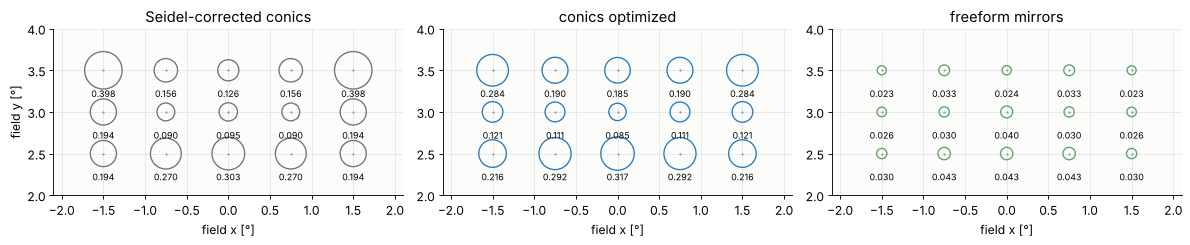

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
sc = None
for k, (name, r) in enumerate([("Seidel-corrected conics", rms_conic),
                               ("conics optimized", rms_conic2), ("freeform mirrors", rms_ff)]):
    sc = oa.plot_full_field(ax[k], F_tma, r, "rms", unit=DEG, scale=sc, color=[GREY, BLUE, GREEN][k])
    for (x, y), v in zip(F_tma/DEG, r):
        ax[k].text(x, y - 0.32, f"{v:.3f}", ha="center", fontsize=8)
    ax[k].set(title=name, xlabel="field x [°]", xlim=(-2.1, 2.1), ylim=(2.0, 4.0))
ax[0].set_ylabel("field y [°]")
plt.tight_layout()
plt.show()

The freeforms bring the worst field point from 0.3 to below 0.05 waves
RMS: diffraction limited over the whole 3° × 1° field, with all beams
still clear. The image scale is held only to 1 or 2 %, and it differs
between x and y (an anamorphic scale, which plane-symmetric off-axis
systems have in general). How large are the
freeform departures, and what does each do? The departure of each mirror
(piston, tilt and power removed, as an optician would measure it against
its best-fit sphere) and, from freeform nodal aberration theory, its
contribution to the astigmatism and coma at the centre and at the
x edges of the field:

mirror  departure P-V   Z5     Z8    | astigmatism Z5+iZ6 [waves] at x = -1.5°, 0, +1.5° | coma Z7+iZ8 at the centre
  M1    4.14e-02 mm  13.67  12.70 µm | 106.32+20.13j  106.39-0.00j  106.32-20.13j | -0.00+59.10j
  M2    3.48e-02 mm -16.41   3.49 µm |  58.85-0.00j   58.85-0.00j   58.85-0.00j | 0.00-18.05j
  M3    4.28e-03 mm   1.32   0.68 µm |   0.30-1.86j    0.57-0.00j    0.30+1.86j | -0.00+0.05j


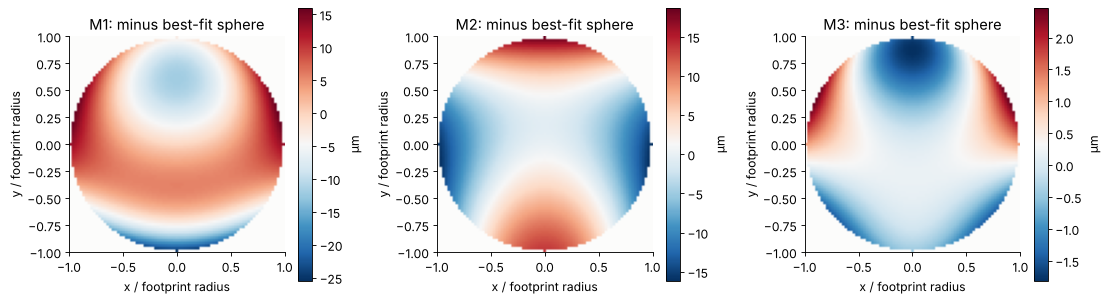

In [16]:
fp_ff = oa.footprints(tma_ff, F_corners)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.0))
H_edges = nd.complex_field([(-1.5*DEG, 3*DEG), centre, (1.5*DEG, 3*DEG)], tma_ff.max_field)
print("mirror  departure P-V   Z5     Z8    | astigmatism Z5+iZ6 [waves] at x = -1.5°, 0, +1.5° "
      "| coma Z7+iZ8 at the centre")
for k, i in enumerate((0, 2, 3)):
    s = tma_ff.surfaces[i]
    zc = dict(s.zernike)
    u = np.linspace(-1, 1, 81)
    U, V = np.meshgrid(u, u)
    x0, y0 = s.centre
    dep = s.departure(x0 + s.norm_radius*U, y0 + s.norm_radius*V)
    A = np.column_stack([np.ones(U.size), U.ravel(), V.ravel(), 2*(U**2 + V**2).ravel() - 1])
    inside = (U**2 + V**2 <= 1).ravel()
    resid = dep.ravel() - A @ np.linalg.lstsq(A[inside], dep.ravel()[inside], rcond=None)[0]
    resid = np.where(inside, resid, np.nan).reshape(U.shape)
    P = nd.freeform_field_zernikes(tma_ff, i, H_edges, 9)
    print(f"  {s.label:4s}  {np.nanmax(resid) - np.nanmin(resid):8.2e} mm "
          f"{zc.get(5, 0)*1e3:6.2f} {zc.get(8, 0)*1e3:6.2f} µm | "
          + "  ".join(f"{v:12.2f}" for v in astig(P)) + f" | {coma(P[1]):.2f}")
    im = ax[k].imshow(resid*1e3, extent=[-1, 1, -1, 1], origin="lower", cmap="RdBu_r")
    plt.colorbar(im, ax=ax[k], label="µm")
    ax[k].set(title=f"{s.label}: minus best-fit sphere",
              xlabel="x / footprint radius", ylabel="y / footprint radius")
    ax[k].grid(False)
plt.tight_layout()
plt.show()

The departures from the best-fit spheres are tens of micrometres, the
same size as the departure of an off-axis conic from its best-fit sphere
(section 1), and within reach of diamond turning and of deterministic
polishing. Freeform nodal aberration theory sorts their effects: the
freeform of M2, which sits in the stop, adds astigmatism and coma that
are the same over the whole field; those of M1 and M3, away from the
stop, add astigmatism that also changes linearly across the field. The
contributions of M1 and M2 are large, up to a hundred waves of
astigmatism and tens of waves of coma, and are balanced by the conic constants, which changed with them
(an off-axis conic is itself an astigmatic and comatic cap, section 1):
the freeform and the conic of a mirror share the work, and only their
sum is small. Balances of large terms are also what makes such designs
sensitive to alignment.

The optimization here started from a good first order layout and a
corrected parent. For larger fields or faster systems, the first order
layout itself (the offsets, the mirror tilts, a folded geometry) needs a
global search (notebook [154 (global optimization and saddle points)](154_global_optimization_saddle_points.ipynb))
or a starting point from the theory (Bauer, Schiesser and Rolland 2018).

## 6. Summary

- An off-axis segment of a conic is an astigmatic and comatic cap
  ($R_s = \sqrt{R^2 - Kh^2}$, $R_t = R_s^3/R^2$): 24 µm of astigmatism on a
  100 mm segment of an f = 500 mm paraboloid at 23° off-axis angle, 0.2
  mm on the outer segments of a JWST-like primary.
- Off-axis systems are traced as their rotationally symmetric parents with
  an aperture offset (a decentred stop) and a field bias. The parent's
  third order coefficients, sampled over the sub-aperture, give the
  linear astigmatism of an off-axis paraboloid to 3 %.
- Nodal aberration theory: each surface contributes its Seidel
  aberrations about its own field centre $\boldsymbol\sigma_j$. A
  decentred secondary of a Ritchey–Chrétien gives constant coma and
  binodal astigmatism, both within about 1 % of the ray trace; tilting
  it about the coma-free pivot removes the coma but leaves the two
  astigmatic nodes in the field.
- Freeform terms at the stop add field-constant aberrations; away from
  the stop they add field-dependent ones (coma brings linear
  astigmatism).
- A Cook three-mirror anastigmat (f = 600 mm, F/4) used off-axis in
  aperture and field clears all mirrors by 12 mm or more. Its parent is
  a perfect third order anastigmat; the 0.1 to 0.4 waves that remain
  over a 3° × 1° field are higher order. Ring fields put the field where
  these are balanced; Zernike freeform departures of tens of micrometres
  on all three mirrors make the whole rectangular field diffraction
  limited (below 0.05 waves RMS).

Related: notebooks [97 (telescope zoo)](97_telescope_zoo.ipynb) (the
coaxial telescopes), [98 (segmented mirrors)](98_segmented_mirrors.ipynb),
[128 (Forbes Q aspheres)](128_forbes_q_aspheres.ipynb),
[126 (head-up displays)](126_head_up_displays.ipynb) (an off-axis freeform
mirror system in a car), [58 (lens optimization)](58_lens_optimization.ipynb)
and [153 (multi-configuration optimization)](153_multiconfig_optimization.ipynb).

## References

- R. V. Shack and K. P. Thompson, "Influence of alignment errors of a telescope system on its aberration field", Proc. SPIE 251, 146-153 (1980).
- K. P. Thompson, "Description of the third-order optical aberrations of near-circular pupil optical systems without symmetry", J. Opt. Soc. Am. A 22, 1389-1401 (2005).
- K. P. Thompson, T. Schmid, O. Cakmakci and J. P. Rolland, "Real-ray-based method for locating individual surface aberration field centers in imaging optical systems without symmetry", J. Opt. Soc. Am. A 26, 1503-1517 (2009).
- T. Schmid, J. P. Rolland, A. Rakich and K. P. Thompson, "Separation of the effects of astigmatic figure error from misalignments using nodal aberration theory (NAT)", Opt. Express 18, 17433-17447 (2010).
- K. Fuerschbach, J. P. Rolland and K. P. Thompson, "Theory of aberration fields for general optical systems with freeform surfaces", Opt. Express 22, 26585-26606 (2014).
- A. Bauer, E. M. Schiesser and J. P. Rolland, "Starting geometry creation and design method for freeform optics", Nat. Commun. 9, 1756 (2018).
- D. R. Cook, "Three-mirror anastigmat used off-axis in aperture and field", US 4,265,510 (1981).
- R. A. Buchroeder, "Tilted component optical systems", PhD thesis, University of Arizona (1976).
- D. Malacara (ed.), "Optical Shop Testing", 3rd ed., Wiley (2007), chapter 18.

In [17]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 44 s
